In [1]:

import torch
import torchvision
import sys

print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
          "GB")
else:
    device = torch.device("cpu")
    print("WARNING: GPU not available!")


Python version: 3.13.15
PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
CUDA available: True
GPU: Tesla T4
GPU memory: 15.64 GB


In [2]:
# Experiment settings. Keep this notebook private while the competition is open.
# RUN ALL from a fresh GPU session. No Kaggle API token or Drive mount is needed.
# Presets: improved_v1 (default), long_only, original_recipe.
import random
import numpy as np

PRESET = "improved_v1"
RUN_NAME = PRESET + "_seed42"
SEED = 42
RESUME_FROM = ""  # Optional path to THIS experiment's latest_resnet.pth.
PUBLIC_KAGGLE_ACCURACY_PERCENT = None  # Enter the exact public score after submission.

presets = {
    "original_recipe": dict(blocks=[3, 3, 3], epochs=60, warmup_epochs=0,
        randaugment=False, mixup_alpha=0.0, mixup_probability=0.0,
        label_smoothing=0.1, erasing_probability=0.15),
    "long_only": dict(blocks=[3, 3, 3], epochs=200, warmup_epochs=5,
        randaugment=False, mixup_alpha=0.0, mixup_probability=0.0,
        label_smoothing=0.1, erasing_probability=0.15),
    "improved_v1": dict(blocks=[4, 4, 3], epochs=200, warmup_epochs=5,
        randaugment=True, mixup_alpha=0.2, mixup_probability=0.5,
        label_smoothing=0.0, erasing_probability=0.0),
}
assert PRESET in presets
CONFIG = dict(presets[PRESET], preset=PRESET, seed=SEED,
    batch_size=128, learning_rate=0.1, momentum=0.9, weight_decay=5e-4,
    minimum_lr=1e-5, randaugment_ops=2, randaugment_magnitude=7,
    validation_fraction=0.10, split_seed=42, num_workers=2,
    channels=[64, 128, 256], stem_channels=32)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print("Selected experiment:", RUN_NAME)
print(CONFIG)

Selected experiment: improved_v1_seed42
{'blocks': [4, 4, 3], 'epochs': 200, 'warmup_epochs': 5, 'randaugment': True, 'mixup_alpha': 0.2, 'mixup_probability': 0.5, 'label_smoothing': 0.0, 'erasing_probability': 0.0, 'preset': 'improved_v1', 'seed': 42, 'batch_size': 128, 'learning_rate': 0.1, 'momentum': 0.9, 'weight_decay': 0.0005, 'minimum_lr': 1e-05, 'randaugment_ops': 2, 'randaugment_magnitude': 7, 'validation_fraction': 0.1, 'split_seed': 42, 'num_workers': 2, 'channels': [64, 128, 256], 'stem_channels': 32}


In [3]:
# Kaggle mounts competition data directly. No credentials are required.
from pathlib import Path
DATA_DIR = Path("/kaggle/input/competitions/cifar-10-res-net-architecture-challenge-dl")
if not (DATA_DIR / "train_labels.csv").is_file():
    alternate = Path("/kaggle/input/cifar-10-res-net-architecture-challenge-dl")
    if (alternate / "train_labels.csv").is_file():
        DATA_DIR = alternate
assert (DATA_DIR / "train_labels.csv").is_file(), (
    "Attach NYU Tandon Deep Learning F26 using Add Input, then rerun."
)
print("Competition data:", DATA_DIR)

Competition data: /kaggle/input/competitions/cifar-10-res-net-architecture-challenge-dl


In [4]:
# Verify mounted files without recursively scanning 52,000 images.
for name in ["train_images", "test_images", "train_labels.csv", "test.csv", "sample_submission.csv"]:
    path = DATA_DIR / name
    assert path.exists(), f"Missing competition input: {path}"
    print(name, "ready")

train_images ready
test_images ready
train_labels.csv ready
test.csv ready
sample_submission.csv ready


In [6]:
# All writable artifacts go to Kaggle working storage.
import json
import hashlib
OUTPUT_DIR = Path("/kaggle/working") / RUN_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_DIR = OUTPUT_DIR  # Preserve the original notebook's variable name.
CONFIG_SIGNATURE = hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()
config_path = OUTPUT_DIR / "config.json"
if config_path.exists():
    previous = json.loads(config_path.read_text())
    assert previous == CONFIG, "Use a new RUN_NAME when changing the configuration."
config_path.write_text(json.dumps(CONFIG, indent=2))
print("Run outputs:", OUTPUT_DIR)

Run outputs: /kaggle/working/improved_v1_seed42


In [7]:
# The original API file-listing cell is unnecessary with attached Kaggle inputs.
print("Data is read directly from the competition input; no API downloads.")

Data is read directly from the competition input; no API downloads.


In [8]:
# Record package/hardware versions for reproduction.
import platform
import torchvision
ENVIRONMENT = {"python": platform.python_version(), "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}
(OUTPUT_DIR / "environment.json").write_text(json.dumps(ENVIRONMENT, indent=2))
print(ENVIRONMENT)

{'python': '3.13.15', 'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'gpu': 'Tesla T4'}


In [9]:
# Original paginated API discovery is replaced by the provided CSV manifests.
import pandas as pd
train_manifest = pd.read_csv(DATA_DIR / "train_labels.csv")
test_manifest = pd.read_csv(DATA_DIR / "test.csv")
print("Training rows:", len(train_manifest))
print("Evaluation rows:", len(test_manifest))

Training rows: 50000
Evaluation rows: 2000


In [10]:
# No pagination, rate-limit retries, or sleeps are needed on Kaggle.
assert {"id", "filename", "label"}.issubset(train_manifest.columns)
assert {"id", "filename"}.issubset(test_manifest.columns)
assert not train_manifest[["id", "filename", "label"]].isna().any().any()
assert not test_manifest[["id", "filename"]].isna().any().any()
print("Required manifest columns verified.")

Required manifest columns verified.


In [11]:
print("Training images listed:", len(train_manifest))
print("Evaluation images listed:", len(test_manifest))
assert len(train_manifest) == 50000
assert len(test_manifest) == 2000
assert train_manifest["id"].is_unique and train_manifest["filename"].is_unique
assert test_manifest["id"].is_unique and test_manifest["filename"].is_unique
assert train_manifest["label"].isin(range(10)).all()

Training images listed: 50000
Evaluation images listed: 2000


In [12]:
# Check dimensions without inspecting or manually labeling evaluation content.
from PIL import Image
for folder, frame in [("train_images", train_manifest), ("test_images", test_manifest)]:
    path = DATA_DIR / folder / frame.iloc[0]["filename"]
    assert path.is_file(), f"Missing image: {path}"
    with Image.open(path) as image:
        assert image.size == (32, 32)
        print(folder, "size:", image.size, "mode:", image.mode)

train_images size: (32, 32) mode: RGB
test_images size: (32, 32) mode: RGB


In [13]:
# Track intended changes separately from measured results.
CHANGES = [
    {"setting": "platform", "original": "Colab / Drive / Kaggle API", "improved_v1": "Kaggle attached input",
     "why": "Use mounted data directly and remove download/mount troubleshooting."},
    {"setting": "epochs", "original": 60, "improved_v1": 200,
     "why": "Give optimization a longer useful learning-rate schedule."},
    {"setting": "warmup_epochs", "original": 0, "improved_v1": 5,
     "why": "Ramp the initial learning rate before cosine decay."},
    {"setting": "residual_blocks", "original": [3,3,3], "improved_v1": [4,4,3],
     "why": "Add two lower-channel blocks while remaining below 5M parameters."},
    {"setting": "RandAugment", "original": "off", "improved_v1": "2 operations, magnitude 7/30",
     "why": "Increase appearance diversity using only permitted training images."},
    {"setting": "MixUp", "original": "off", "improved_v1": "alpha 0.2, probability 0.5",
     "why": "Regularize by blending training images and their target losses."},
    {"setting": "label_smoothing", "original": 0.1, "improved_v1": 0.0,
     "why": "Avoid stacking label smoothing on top of mixed targets in this candidate."},
    {"setting": "random_erasing_probability", "original": 0.15, "improved_v1": 0.0,
     "why": "Avoid stacking additional occlusion on the stronger augmentation recipe."},
    {"setting": "inference", "original": "original image only", "improved_v1": "validation-selected original or original+flip",
     "why": "Test a parameter-free inference change using labeled validation data only."},
    {"setting": "records", "original": "checkpoint history", "improved_v1": "config, history CSV, plots, results, change log",
     "why": "Make the experiment reproducible and support the report."},
]
REFERENCES = {
    "ResNet": "https://arxiv.org/abs/1512.03385",
    "RandAugment": "https://arxiv.org/abs/1909.13719",
    "MixUp": "https://arxiv.org/abs/1710.09412",
    "related NYU project (architecture inspiration only)": "https://arxiv.org/abs/2306.12100",
}
(OUTPUT_DIR / "changes.json").write_text(json.dumps(CHANGES, indent=2))
(OUTPUT_DIR / "references.json").write_text(json.dumps(REFERENCES, indent=2))
print("Change log and references saved. New accuracy is not yet measured.")
print("improved_v1 changes several settings together; use controlled follow-up runs to attribute gains.")
notes_lines = ["# Experiment changes", "", "Default candidate: improved_v1. Results are pending until execution.", "", "| Setting | Original | Improved v1 | Reason |", "| --- | --- | --- | --- |"]
for change in CHANGES:
    notes_lines.append(f"| {change['setting']} | {change['original']} | {change['improved_v1']} | {change['why']} |")
notes_lines.extend(["", "This is a bundled experiment. A gain does not identify which individual change caused it.",
    "Use long_only to isolate the longer schedule package while retaining the original architecture and augmentation.",
    "The original_recipe preset reproduces the original recipe, not its exact historical weights or hardware-dependent result.",
    "Use a fresh session/new RUN_NAME when changing settings. Attach both checkpoints to resume.",
    "The original checkpoint and Kaggle score are not independently re-evaluated in this training notebook.",
    "", "## References"])
notes_lines.extend(f"- {name}: {url}" for name, url in REFERENCES.items())
(OUTPUT_DIR / "experiment_notes.md").write_text("\n".join(notes_lines) + "\n")


Change log and references saved. New accuracy is not yet measured.
improved_v1 changes several settings together; use controlled follow-up runs to attribute gains.


2096

In [14]:
# Google Drive is not needed. Kaggle output must be saved/downloaded after running.
print("Output folder:", OUTPUT_DIR)
print("After training, Save Version with outputs and download checkpoints/logs.")
print("An interrupted session's unsaved /kaggle/working files are not a durable backup.")

Output folder: /kaggle/working/improved_v1_seed42
After training, Save Version with outputs and download checkpoints/logs.
An interrupted session's unsaved /kaggle/working files are not a durable backup.


In [15]:
# Competition images are already extracted and mounted read-only.
print("Training directory:", DATA_DIR / "train_images")
print("Evaluation directory:", DATA_DIR / "test_images")

Training directory: /kaggle/input/competitions/cifar-10-res-net-architecture-challenge-dl/train_images
Evaluation directory: /kaggle/input/competitions/cifar-10-res-net-architecture-challenge-dl/test_images


In [16]:
# Compact inspection instead of printing every image filename.
print("Top-level inputs:")
for item in DATA_DIR.iterdir():
    print(item.name)

Top-level inputs:
sample_submission.csv
train_images
train_labels.csv
test.csv
test_images


In [17]:
# The CSV manifests are the source of truth for file ordering and labels.
print("Training examples:")
print(train_manifest.head())
print("Evaluation manifest columns:", test_manifest.columns.tolist())

Training examples:
   id         filename  label
0   0  train_00000.png      6
1   1  train_00001.png      9
2   2  train_00002.png      9
3   3  train_00003.png      4
4   4  train_00004.png      1
Evaluation manifest columns: ['id', 'filename']


In [18]:
# ZIP inspection is unnecessary for mounted competition files.
print("No ZIP extraction or image moves are required.")

No ZIP extraction or image moves are required.


In [19]:
# Preserve the original directory variables without writing to read-only inputs.
train_dir = DATA_DIR / "train_images"
test_dir = DATA_DIR / "test_images"
print("Training rows:", len(train_manifest))
print("Evaluation rows:", len(test_manifest))

Training rows: 50000
Evaluation rows: 2000


In [20]:
import pandas as pd
from pathlib import Path

# DATA_DIR was set from the attached Kaggle competition.

train_df = pd.read_csv(DATA_DIR / "train_labels.csv")

print("Dataset shape:", train_df.shape)

print("\nColumn names:")
print(train_df.columns.tolist())

print("\nFirst 10 rows:")
print(train_df.head(10))

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nLabel distribution:")
print(train_df.iloc[:, -1].value_counts().sort_index())

Dataset shape: (50000, 3)

Column names:
['id', 'filename', 'label']

First 10 rows:
   id         filename  label
0   0  train_00000.png      6
1   1  train_00001.png      9
2   2  train_00002.png      9
3   3  train_00003.png      4
4   4  train_00004.png      1
5   5  train_00005.png      1
6   6  train_00006.png      2
7   7  train_00007.png      7
8   8  train_00008.png      8
9   9  train_00009.png      3

Missing values:
id          0
filename    0
label       0
dtype: int64

Label distribution:
label
0    5000
1    5000
2    5000
3    5000
4    5000
5    5000
6    5000
7    5000
8    5000
9    5000
Name: count, dtype: int64


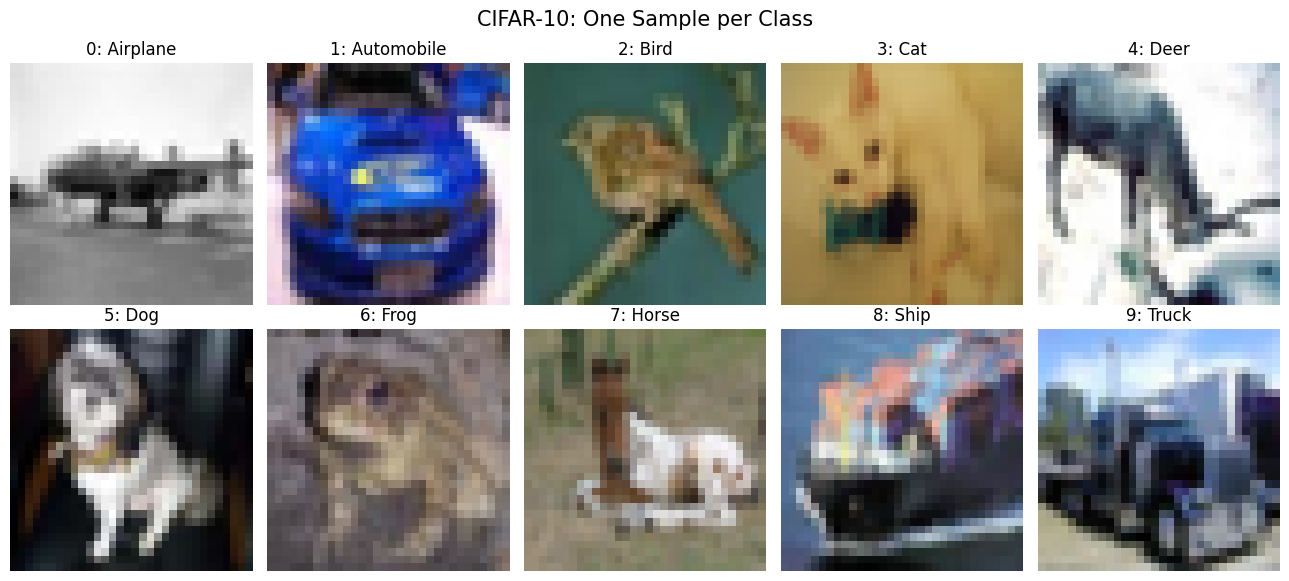

Image dimensions: (32, 32)
Image mode: RGB


In [21]:

import matplotlib.pyplot as plt
from PIL import Image

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

# Select one image from each class
samples = (
    train_df.groupby("label")
    .sample(n=1, random_state=42)
    .sort_values("label")
)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    image_path = DATA_DIR / "train_images" / row["filename"]
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(f"{row['label']}: {class_names[row['label']]}")
    ax.axis("off")

plt.suptitle("CIFAR-10: One Sample per Class", fontsize=15)
plt.tight_layout()
plt.show()

# Verify image dimensions
image = Image.open(
    DATA_DIR / "train_images" / train_df.iloc[0]["filename"]
)

print("Image dimensions:", image.size)
print("Image mode:", image.mode)


In [22]:
from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    train_df,
    test_size=0.10,
    random_state=42,
    stratify=train_df["label"]
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))

print("\nTraining class distribution:")
print(train_data["label"].value_counts().sort_index())

print("\nValidation class distribution:")
print(val_data["label"].value_counts().sort_index())

# Ensure there is no overlap
assert set(train_data["id"]).isdisjoint(set(val_data["id"]))

print("\nSplit successful! No overlapping images.")

train_data.to_csv(OUTPUT_DIR / "train_split.csv", index=False)
val_data.to_csv(OUTPUT_DIR / "validation_split.csv", index=False)

Training samples: 45000
Validation samples: 5000

Training class distribution:
label
0    4500
1    4500
2    4500
3    4500
4    4500
5    4500
6    4500
7    4500
8    4500
9    4500
Name: count, dtype: int64

Validation class distribution:
label
0    500
1    500
2    500
3    500
4    500
5    500
6    500
7    500
8    500
9    500
Name: count, dtype: int64

Split successful! No overlapping images.


In [23]:
import torch
from torchvision import transforms
from torchvision.transforms import InterpolationMode

CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

train_operations = [
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
]
if CONFIG["randaugment"]:
    train_operations.append(transforms.RandAugment(
        num_ops=CONFIG["randaugment_ops"],
        magnitude=CONFIG["randaugment_magnitude"],
        interpolation=InterpolationMode.BILINEAR,
        fill=tuple(round(255 * mean) for mean in CIFAR_MEAN),
    ))
train_operations.extend([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
if CONFIG["erasing_probability"] > 0:
    train_operations.append(transforms.RandomErasing(
        p=CONFIG["erasing_probability"], scale=(0.02, 0.12), ratio=(0.3, 3.3)))
train_transform = transforms.Compose(train_operations)
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
print("Training transformations:", train_transform)
print("Validation transformations:", val_transform)

Training transformations: Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    RandAugment(num_ops=2, magnitude=7, num_magnitude_bins=31, interpolation=InterpolationMode.BILINEAR, fill=(125, 123, 114))
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)
Validation transformations: Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)


In [25]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch

class CIFAR10CustomDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = self.image_dir / row["filename"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = CIFAR10CustomDataset(
    train_data,
    DATA_DIR / "train_images",
    train_transform
)

val_dataset = CIFAR10CustomDataset(
    val_data,
    DATA_DIR / "train_images",
    val_transform
)

BATCH_SIZE = CONFIG["batch_size"]

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    worker_init_fn=seed_worker,
    generator=loader_generator,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    worker_init_fn=seed_worker,
    generator=loader_generator,
    pin_memory=True
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Test one batch
images, labels = next(iter(train_loader))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label range:", labels.min().item(), "to", labels.max().item())

assert images.shape == (128, 3, 32, 32)
assert labels.min() >= 0 and labels.max() <= 9

print("\nDataLoader verification successful!")

Training images: 45000
Validation images: 5000
Training batches: 352
Validation batches: 40

Batch image shape: torch.Size([128, 3, 32, 32])
Batch label shape: torch.Size([128])
Image data type: torch.float32
Label range: 0 to 9

DataLoader verification successful!


In [26]:

import torch
import torch.nn as nn

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=stride,
            padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Match dimensions when channels or resolution change
        self.shortcut = nn.Identity()

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + identity
        out = self.relu(out)

        return out


# Verify the block
block = ResidualBlock(32, 64, stride=2)

test_input = torch.randn(4, 32, 32, 32)

test_output = block(test_input)

print("Input shape:", test_input.shape)
print("Output shape:", test_output.shape)

assert test_output.shape == (4, 64, 16, 16)

print("\nResidual block verification successful!")


Input shape: torch.Size([4, 32, 32, 32])
Output shape: torch.Size([4, 64, 16, 16])

Residual block verification successful!


In [27]:
import torch
import torch.nn as nn

class CustomResNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.in_channels = 32

        # Initial convolution for 32x32 CIFAR images
        self.stem = nn.Sequential(
            nn.Conv2d(
                3, 32, kernel_size=3,
                stride=1, padding=1, bias=False
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        # Residual stages
        self.layer1 = self._make_layer(64, blocks=CONFIG["blocks"][0], stride=1)
        self.layer2 = self._make_layer(128, blocks=CONFIG["blocks"][1], stride=2)
        self.layer3 = self._make_layer(256, blocks=CONFIG["blocks"][2], stride=2)

        # Classification head
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(256, num_classes)

    def _make_layer(self, out_channels, blocks, stride):
        layers = [
            ResidualBlock(
                self.in_channels, out_channels, stride
            )
        ]

        self.in_channels = out_channels

        for _ in range(1, blocks):
            layers.append(
                ResidualBlock(out_channels, out_channels)
            )

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.stem(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)

        return x


# Create model
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = CustomResNet(num_classes=10).to(device)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Device:", device)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Parameter limit: {5_000_000:,}")

# Verify architecture using a sample batch
test_input = torch.randn(4, 3, 32, 32).to(device)

model.eval()
with torch.no_grad():
    test_output = model(test_input)

print("\nInput shape:", test_input.shape)
print("Output shape:", test_output.shape)

assert trainable_params <= 5_000_000, \
    "Model exceeds the parameter limit!"

assert test_output.shape == (4, 10), \
    "Incorrect model output shape!"

print("\nCustom ResNet verification successful!")

Device: cuda
Total parameters: 4,679,978
Trainable parameters: 4,679,978
Parameter limit: 5,000,000

Input shape: torch.Size([4, 3, 32, 32])
Output shape: torch.Size([4, 10])

Custom ResNet verification successful!


In [28]:
import torch
import torch.nn as nn
import torch.optim as optim
import math

EPOCHS = CONFIG["epochs"]
LEARNING_RATE = CONFIG["learning_rate"]
WEIGHT_DECAY = CONFIG["weight_decay"]
criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG["label_smoothing"])
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE,
    momentum=CONFIG["momentum"], weight_decay=WEIGHT_DECAY, nesterov=True)

def learning_rate_multiplier(epoch):
    warmup = CONFIG["warmup_epochs"]
    if epoch < warmup:
        return (epoch + 1) / warmup
    progress = min(1.0, max(0.0, (epoch - warmup) / max(1, EPOCHS - warmup - 1)))
    floor = CONFIG["minimum_lr"] / LEARNING_RATE
    return floor + (1.0 - floor) * (1.0 + math.cos(math.pi * progress)) / 2.0

if PRESET == "original_recipe":
    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS, eta_min=CONFIG["minimum_lr"])
else:
    scheduler = optim.lr_scheduler.LambdaLR(optimizer, learning_rate_multiplier)

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = CHECKPOINT_DIR / "best_resnet.pth"
LATEST_MODEL_PATH = CHECKPOINT_DIR / "latest_resnet.pth"
history = {key: [] for key in ["train_loss", "train_acc", "val_loss", "val_acc", "learning_rate", "epoch_seconds"]}
best_val_acc = 0.0
print("Epochs:", EPOCHS, "| batch size:", BATCH_SIZE)
print("Optimizer:", type(optimizer).__name__, "| scheduler:", type(scheduler).__name__)
print("Best checkpoint:", BEST_MODEL_PATH)
print("Train accuracy is MixUp-weighted when MixUp is used; it is not directly comparable to the original.")

Epochs: 200 | batch size: 128
Optimizer: SGD | scheduler: LambdaLR
Best checkpoint: /kaggle/working/improved_v1_seed42/checkpoints/best_resnet.pth
Train accuracy is MixUp-weighted when MixUp is used; it is not directly comparable to the original.


In [29]:
from tqdm.auto import tqdm
import torch

scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = correct = total = 0
    progress = tqdm(loader, desc="Training", leave=False)
    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        use_mixup = (CONFIG["mixup_alpha"] > 0 and
                     np.random.random() < CONFIG["mixup_probability"])
        lam = 1.0
        other_labels = labels
        if use_mixup:
            lam = float(np.random.beta(CONFIG["mixup_alpha"], CONFIG["mixup_alpha"]))
            permutation = torch.randperm(images.size(0), device=device)
            images = lam * images + (1.0 - lam) * images[permutation]
            other_labels = labels[permutation]
        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            outputs = model(images)
            loss = lam * criterion(outputs, labels) + (1.0 - lam) * criterion(outputs, other_labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += lam * (predictions == labels).sum().item()
        correct += (1.0 - lam) * (predictions == other_labels).sum().item()
        total += labels.size(0)
        progress.set_postfix(loss=f"{running_loss / total:.4f}", acc=f"{100 * correct / total:.2f}%")
    return running_loss / total, 100 * correct / total

@torch.no_grad()
def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = correct = total = 0
    for images, labels in tqdm(loader, desc="Validation", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            outputs = model(images)
            loss = criterion(outputs, labels)
        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100 * correct / total

print("Training and validation functions ready; mixed precision:", scaler.is_enabled())

Training and validation functions ready; mixed precision: True


In [30]:
import time
import torch

def capture_random_state():
    state = np.random.get_state()
    return {"python": random.getstate(), "numpy": [state[0], state[1].tolist(), state[2], state[3], state[4]],
        "torch": torch.get_rng_state(), "loader": loader_generator.get_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}

def restore_random_state(state):
    random.setstate(state["python"])
    a = state["numpy"]
    np.random.set_state((a[0], np.asarray(a[1], dtype=np.uint32), a[2], a[3], a[4]))
    torch.set_rng_state(state["torch"].cpu())
    loader_generator.set_state(state["loader"].cpu())
    if torch.cuda.is_available() and state["cuda"]:
        torch.cuda.set_rng_state_all([item.cpu() for item in state["cuda"]])

def run_training(start_epoch=0, end_epoch=None):
    global best_val_acc
    stop_epoch = EPOCHS if end_epoch is None else min(end_epoch, EPOCHS)
    for epoch in range(start_epoch, stop_epoch):
        start_time = time.time()
        print(f"\nEpoch {epoch + 1}/{EPOCHS}")
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc = validate_one_epoch(model, val_loader, criterion, device)
        current_lr = optimizer.param_groups[0]["lr"]
        scheduler.step()
        values = [train_loss, train_acc, val_loss, val_acc, current_lr, time.time() - start_time]
        for key, value in zip(history, values):
            history[key].append(value)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save({"epoch": epoch + 1, "model_state_dict": model.state_dict(),
                "val_acc": val_acc, "train_acc": train_acc, "config": CONFIG,
                "config_signature": CONFIG_SIGNATURE, "trainable_parameters": trainable_params}, BEST_MODEL_PATH)
            print("New best model saved!")
        torch.save({"epoch": epoch + 1, "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(), "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(), "best_val_acc": best_val_acc,
            "history": history, "config": CONFIG, "config_signature": CONFIG_SIGNATURE,
            "random_state": capture_random_state()}, LATEST_MODEL_PATH)
        pd.DataFrame(history).rename_axis("epoch_zero_based").to_csv(OUTPUT_DIR / "history.csv")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
        print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")
        print(f"LR: {current_lr:.6f} | Time: {history['epoch_seconds'][-1]:.1f}s | Best: {best_val_acc:.2f}%")
    print("Completed epochs:", len(history["val_acc"]))

print("Main training loop configured.")

Main training loop configured.


In [31]:
# Keep the original one-epoch smoke test, but do not reset the full schedule.
start_epoch = 0
if not RESUME_FROM:
    assert not LATEST_MODEL_PATH.exists(), (
        "This RUN_NAME already has a checkpoint. Set RESUME_FROM to it, or use a new RUN_NAME."
    )
    run_training(start_epoch=0, end_epoch=1)
    start_epoch = 1
else:
    print("Smoke test skipped; the next cell will restore the selected checkpoint.")


Epoch 1/200


Training:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

New best model saved!
Train Loss: 1.5999 | Train Acc: 43.24%
Val Loss: 1.0872 | Val Acc: 60.78%
LR: 0.020000 | Time: 141.2s | Best: 60.78%
Completed epochs: 1


In [32]:
# Optional resume is restricted to this exact configuration.
if RESUME_FROM:
    resume_path = Path(RESUME_FROM)
    checkpoint = torch.load(resume_path, map_location=device, weights_only=True)
    assert checkpoint.get("config_signature") == CONFIG_SIGNATURE, (
        "Checkpoint configuration differs. Do not resume a 60-epoch or different-architecture run here."
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    best_val_acc = checkpoint["best_val_acc"]
    history = checkpoint["history"]
    start_epoch = checkpoint["epoch"]
    restore_random_state(checkpoint["random_state"])
    # Preserve the earlier best even if remaining epochs do not improve it.
    import shutil
    sibling_best = resume_path.parent / "best_resnet.pth"
    assert sibling_best.is_file(), "Attach both best_resnet.pth and latest_resnet.pth when resuming."
    previous_best = torch.load(sibling_best, map_location="cpu", weights_only=True)
    assert previous_best.get("config_signature") == CONFIG_SIGNATURE
    assert abs(previous_best["val_acc"] - best_val_acc) < 1e-6
    if sibling_best.resolve() != BEST_MODEL_PATH.resolve():
        shutil.copy2(sibling_best, BEST_MODEL_PATH)
print("Completed epochs:", start_epoch)
print("Remaining epochs:", EPOCHS - start_epoch)
print("Current learning rate:", optimizer.param_groups[0]["lr"])

Completed epochs: 1
Remaining epochs: 199
Current learning rate: 0.04000000000000001


In [ ]:

# Resume training from the saved checkpoint
run_training(start_epoch=start_epoch)


In [34]:
import torch

best_checkpoint = torch.load(BEST_MODEL_PATH, map_location=device, weights_only=True)
assert best_checkpoint["config_signature"] == CONFIG_SIGNATURE
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()
val_loss, val_acc = validate_one_epoch(model, val_loader, criterion, device)
print("Best checkpoint epoch:", best_checkpoint["epoch"])
print(f"Verified validation accuracy: {val_acc:.2f}%")
assert abs(val_acc - best_checkpoint["val_acc"]) <= 0.10, "Unexpected validation mismatch; investigate before submitting."

# Select inference using validation labels only; ties retain plain inference.
@torch.inference_mode()
def compare_validation_inference():
    plain_correct = flip_correct = total = 0
    for images, labels in tqdm(val_loader, desc="Compare validation inference"):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            logits = model(images)
            flipped_logits = model(torch.flip(images, dims=[3]))
        plain = logits.float().softmax(dim=1)
        averaged = (plain + flipped_logits.float().softmax(dim=1)) / 2
        plain_correct += (plain.argmax(1) == labels).sum().item()
        flip_correct += (averaged.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return 100 * plain_correct / total, 100 * flip_correct / total

plain_val_acc, flip_val_acc = compare_validation_inference()
USE_FLIP_TTA = flip_val_acc > plain_val_acc
selected_val_acc = flip_val_acc if USE_FLIP_TTA else plain_val_acc
print(f"Plain validation: {plain_val_acc:.2f}% | Flip averaging: {flip_val_acc:.2f}%")
print("Use flip averaging:", USE_FLIP_TTA)
print("These are validation scores, not hidden evaluation accuracy.")

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Best checkpoint epoch: 161
Verified validation accuracy: 94.42%


Compare validation inference:   0%|          | 0/40 [00:00<?, ?it/s]

Plain validation: 94.42% | Flip averaging: 95.14%
Use flip averaging: True
These are validation scores, not hidden evaluation accuracy.


In [35]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from pathlib import Path
import pandas as pd

TEST_DIR = DATA_DIR / "test_images"

# Use the official ID/filename manifest, not guessed filename ordering.
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample_df = pd.read_csv(DATA_DIR / "sample_submission.csv")
assert test_df["id"].is_unique and sample_df["id"].is_unique
assert set(test_df["id"]) == set(sample_df["id"])
test_df = test_df.set_index("id").loc[sample_df["id"]].reset_index()
test_files = [TEST_DIR / filename for filename in test_df["filename"]]

class CIFAR10TestDataset(Dataset):
    def __init__(self, image_files, transform):
        self.image_files = image_files
        self.transform = transform

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        image_path = self.image_files[idx]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        return image


test_dataset = CIFAR10TestDataset(
    test_files,
    val_transform
)

# Avoid multiprocessing warnings during inference
test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))
print("First 5 filenames:", [p.name for p in test_files[:5]])
print("Last 5 filenames:", [p.name for p in test_files[-5:]])

# Verify one batch
test_batch = next(iter(test_loader))
print("\nTest batch shape:", test_batch.shape)

assert len(test_dataset) == 2000
assert test_batch.shape == (128, 3, 32, 32)

print("\nTest DataLoader verification successful!")

Test images: 2000
Test batches: 16
First 5 filenames: ['test_0000.png', 'test_0001.png', 'test_0002.png', 'test_0003.png', 'test_0004.png']
Last 5 filenames: ['test_1995.png', 'test_1996.png', 'test_1997.png', 'test_1998.png', 'test_1999.png']

Test batch shape: torch.Size([128, 3, 32, 32])

Test DataLoader verification successful!


In [36]:
import torch
import numpy as np
from tqdm.auto import tqdm

model.eval()
all_predictions = []
with torch.inference_mode():
    for images in tqdm(test_loader, desc="Predicting evaluation images"):
        images = images.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            outputs = model(images)
            flipped_outputs = model(torch.flip(images, dims=[3])) if USE_FLIP_TTA else None
        probabilities = outputs.float().softmax(dim=1)
        if USE_FLIP_TTA:
            probabilities = (probabilities + flipped_outputs.float().softmax(dim=1)) / 2
        all_predictions.extend(probabilities.argmax(dim=1).cpu().tolist())
assert len(all_predictions) == len(test_df)
assert all(0 <= value <= 9 for value in all_predictions)
print("Total predictions:", len(all_predictions))
print("Inference:", "original + horizontal flip" if USE_FLIP_TTA else "original only")
print("Hidden accuracy is unknown until Kaggle scores the CSV.")

Predicting evaluation images:   0%|          | 0/16 [00:00<?, ?it/s]

Total predictions: 2000
Inference: original + horizontal flip
Hidden accuracy is unknown until Kaggle scores the CSV.


In [37]:
import pandas as pd

submission_df = sample_df[["id"]].copy()
submission_df["label"] = all_predictions
assert submission_df.columns.tolist() == ["id", "label"]
assert submission_df["id"].tolist() == sample_df["id"].tolist()
assert len(submission_df) == len(test_df) == 2000
assert submission_df["id"].is_unique
assert submission_df["label"].isin(range(10)).all()
SUBMISSION_PATH = OUTPUT_DIR / "submission.csv"
submission_df.to_csv(SUBMISSION_PATH, index=False)
# Root copy is convenient in Kaggle's output picker.
submission_df.to_csv("/kaggle/working/submission.csv", index=False)
print(submission_df.head())
print("Submission saved:", SUBMISSION_PATH)

   id  label
0   0      6
1   1      3
2   2      3
3   3      1
4   4      3
Submission saved: /kaggle/working/improved_v1_seed42/submission.csv


In [38]:
# Verify against the mounted sample without any API downloads.
verified_submission = pd.read_csv(SUBMISSION_PATH)
assert verified_submission.columns.tolist() == sample_df.columns.tolist() == ["id", "label"]
assert verified_submission["id"].tolist() == sample_df["id"].tolist()
assert len(verified_submission) == len(sample_df)
assert verified_submission["label"].isin(range(10)).all()
assert pd.api.types.is_integer_dtype(verified_submission["label"])
import hashlib
SUBMISSION_SHA256 = hashlib.sha256(SUBMISSION_PATH.read_bytes()).hexdigest()
print("Submission format verified. SHA256:", SUBMISSION_SHA256)

Submission format verified. SHA256: c60db03901d8ed08e844e6f08cf3c1b03e844ecdf6303c036f7401532828da73


In [39]:
# Submission remains manual: running this notebook never spends a submission slot.
print("No prediction file has been submitted automatically.")
print("Save this notebook version with outputs, then submit /kaggle/working/submission.csv")
print("through the competition's Submit Predictions page when ready.")
print("Team limit in the supplied rules: 5 submissions per day.")

No prediction file has been submitted automatically.
Save this notebook version with outputs, then submit /kaggle/working/submission.csv
through the competition's Submit Predictions page when ready.
Team limit in the supplied rules: 5 submissions per day.


                       run  parameters  best_epoch  plain_val_percent  selected_val_percent public_kaggle_percent                                                                                           notes
teammate_original_reported     4310570          55              94.88                 94.88                  None Previously reported baseline; Kaggle approximately 85%, exact score unverified; not rerun here.
        improved_v1_seed42     4679978         161              94.42                 95.14                  None                                Measured in this run; enter exact public score after submission.


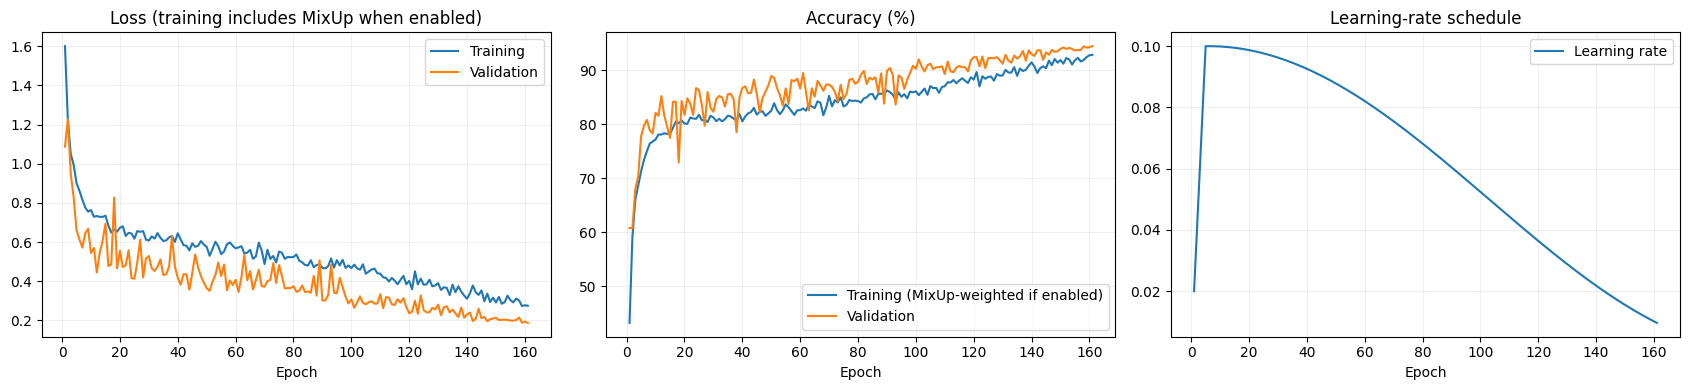

Saved config, changes, references, split manifests, checkpoints, history, results, comparison, and plots.
After a Kaggle submission, enter its exact percentage in PUBLIC_KAGGLE_ACCURACY_PERCENT
and rerun only this final cell to update the experiment record.


In [40]:
# Experiment record, comparison table, and plots for the report.
import matplotlib.pyplot as plt

results = {"run_name": RUN_NAME, "preset": PRESET, "config": CONFIG,
    "trainable_parameters": trainable_params, "best_epoch": best_checkpoint["epoch"],
    "completed_epochs": len(history["val_acc"]),
    "plain_validation_accuracy_percent": plain_val_acc,
    "flip_validation_accuracy_percent": flip_val_acc,
    "selected_validation_accuracy_percent": selected_val_acc,
    "use_flip_tta": USE_FLIP_TTA,
    "public_kaggle_accuracy_percent": PUBLIC_KAGGLE_ACCURACY_PERCENT,
    "private_kaggle_accuracy_percent": None,
    "submission_sha256": SUBMISSION_SHA256,
    "total_training_seconds": sum(history["epoch_seconds"]),
    "environment": ENVIRONMENT,
    "interpretation": "Bundled candidate; improvements cannot be attributed to individual changes without ablations."}
(OUTPUT_DIR / "results.json").write_text(json.dumps(results, indent=2))
comparison = pd.DataFrame([
    {"run": "teammate_original_reported", "parameters": 4310570,
     "best_epoch": 55, "plain_val_percent": 94.88, "selected_val_percent": 94.88,
     "public_kaggle_percent": None,
     "notes": "Previously reported baseline; Kaggle approximately 85%, exact score unverified; not rerun here."},
    {"run": RUN_NAME, "parameters": trainable_params,
     "best_epoch": best_checkpoint["epoch"], "plain_val_percent": plain_val_acc,
     "selected_val_percent": selected_val_acc,
     "public_kaggle_percent": PUBLIC_KAGGLE_ACCURACY_PERCENT,
     "notes": "Measured in this run; enter exact public score after submission."},
])
comparison.to_csv(OUTPUT_DIR / "experiment_comparison.csv", index=False)
print(comparison.to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
epochs_axis = range(1, len(history["val_acc"]) + 1)
axes[0].plot(epochs_axis, history["train_loss"], label="Training")
axes[0].plot(epochs_axis, history["val_loss"], label="Validation")
axes[0].set_title("Loss (training includes MixUp when enabled)")
axes[1].plot(epochs_axis, history["train_acc"], label="Training (MixUp-weighted if enabled)")
axes[1].plot(epochs_axis, history["val_acc"], label="Validation")
axes[1].set_title("Accuracy (%)")
axes[2].plot(epochs_axis, history["learning_rate"], label="Learning rate")
axes[2].set_title("Learning-rate schedule")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_curves.png", dpi=160)
plt.show()
print("Saved config, changes, references, split manifests, checkpoints, history, results, comparison, and plots.")
print("After a Kaggle submission, enter its exact percentage in PUBLIC_KAGGLE_ACCURACY_PERCENT")
print("and rerun only this final cell to update the experiment record.")

In [41]:
import os
import sys
import subprocess
from pathlib import Path
import pandas as pd
from kaggle_secrets import UserSecretsClient

submission_path = Path("/kaggle/working/submission.csv")
sample_path = Path(
    "/kaggle/input/competitions/"
    "cifar-10-res-net-architecture-challenge-dl/"
    "sample_submission.csv"
)

assert submission_path.is_file(), (
    "Run the prediction and CSV-saving cells first."
)

submission = pd.read_csv(submission_path)
sample = pd.read_csv(sample_path)

assert submission.columns.tolist() == ["id", "label"]
assert len(submission) == len(sample)
assert submission["id"].is_unique
assert submission["id"].tolist() == sample["id"].tolist()
assert pd.api.types.is_integer_dtype(submission["label"])
assert submission["label"].isin(range(10)).all()

# Install/update only the Kaggle client.
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"],
    check=True,
)

# Pass the secret to the subprocess without printing it.
submission_env = os.environ.copy()
submission_env["KAGGLE_API_TOKEN"] = (
    UserSecretsClient().get_secret("KAGGLE_API_TOKEN").strip()
)

result = subprocess.run(
    [
        "kaggle", "competitions", "submit",
        "-c", "cifar-10-res-net-architecture-challenge-dl",
        "-f", str(submission_path),
        "-m", "improved_v1: ResNet 4.68M, 200 epochs, RandAugment, MixUp",
    ],
    env=submission_env,
    capture_output=True,
    text=True,
)

# Redact the credential if an error happens to include it.
response = (result.stdout + "\n" + result.stderr).replace(
    submission_env["KAGGLE_API_TOKEN"], "[REDACTED]"
)
print(response)

if result.returncode != 0:
    raise RuntimeError(
        "Submission was not confirmed. Check the response and "
        "competition Submissions tab before retrying."
    )

Submission ref: 57895020
3 submissions remaining today.
Successfully submitted to NYU Tandon Deep Learning F26 

  0%|          | 0.00/12.6k [00:00<?, ?B/s]
100%|██████████| 12.6k/12.6k [00:00<00:00, 32.4kB/s]

